#### Вырезка прямоугольной области с оригинальным текстом и заливка фоном

Изображение сохранено: RedrawFr/output.bmp


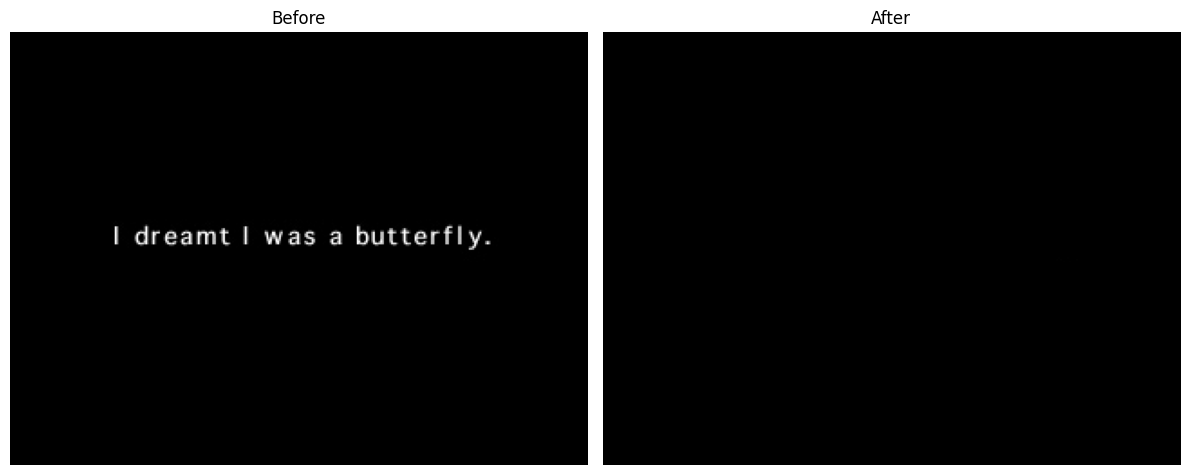

In [20]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display
from sympy.matrices.expressions.blockmatrix import bc_unpack


def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    
    Параметры:
    - image_path: путь к исходному изображению
    - output_path: путь для сохранения результата
    - x, y: координаты верхнего левого угла прямоугольника
    - w, h: ширина и высота прямоугольника
    - fill_color: цвет заливки (по умолчанию белый)
    """
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    pixel = img[0, 0]  # в OpenCV сначала y, потом x
    # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    blue, green, red = pixel
    fill_color = (blue, green, red)
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = fill_color
    
    # Сохранение результата
    cv2.imwrite(output_path, img)
    print(f"Изображение сохранено: {output_path}")
    
    # Открытие изображений
    img_start = Image.open(image_path)
    img_finish = Image.open(output_path)
    
    # Создание двух подграфиков горизонтально
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
    
    # Отображение первого изображения
    ax1.imshow(img_start)
    ax1.set_title('Before')
    ax1.axis('off')
    
    # Отображение второго изображения
    ax2.imshow(img_finish)
    ax2.set_title('After')
    ax2.axis('off')
    
    plt.tight_layout()
    plt.show()
    



# Параметры
input_image = "RedrawFr1/MV1C.STR[0][0034].bmp"      # путь к исходному изображению
output_image = "RedrawFr1/output.bmp"    # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 52, 103    # координаты верхнего левого угла
width = 224       # ширина области
height = 22      # высота области


remove_rectangular_area(input_image, output_image, x, y, width, height)
   

#### Вставка в центр переведенный текст

Изображение сохранено: RedrawFr/output_1.bmp


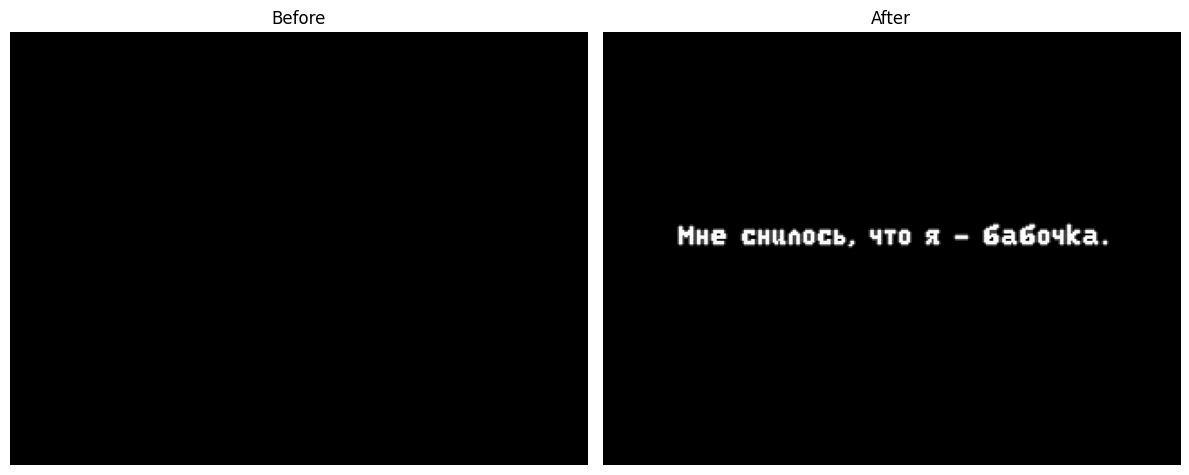

In [17]:
import cv2
import numpy as np

def paste_opencv(b_path, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    base = cv2.imread(b_path)
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    base[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return base

base_path = 'RedrawFr1/output.bmp'
overlay_path = 'RedrawFr1/phrase_1.png'
output_path = 'RedrawFr1/output_1.bmp'

# Использование
result = paste_opencv(base_path, overlay_path, position=(41, 106))
cv2.imwrite(output_path, result)
print(f"Изображение сохранено: {output_path}")

# Открытие изображений
img_start = Image.open(base_path)
img_finish = Image.open(output_path)

# Создание двух подграфиков горизонтально
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Отображение первого изображения
ax1.imshow(img_start)
ax1.set_title('Before')
ax1.axis('off')

# Отображение второго изображения
ax2.imshow(img_finish)
ax2.set_title('After')
ax2.axis('off')

plt.tight_layout()
plt.show()

#### Весь код для изменения одного кадра 1 фразы

Изображение сохранено: RedrawFr/output.bmp


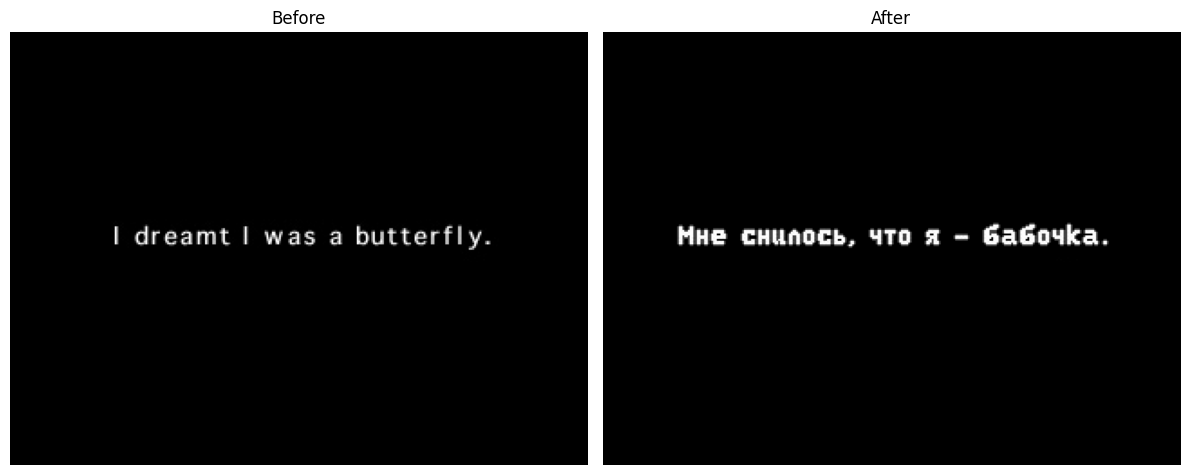

In [22]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    """
    
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    pixel = img[0, 0]  # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = pixel
    
    return img
    
    
def paste_opencv(b_img, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    b_img[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return b_img

    
# Параметры
input_image = "RedrawFr1/MV1C.STR[0][0034].bmp"      # путь к исходному изображению
overlay_image = 'RedrawFr1/phrase_1.png'              # путь к переведенной надписи
output_image = "RedrawFr1/output.bmp"                # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 52, 103    # координаты верхнего левого угла
width = 224       # ширина области
height = 22      # высота области

base_img = remove_rectangular_area(input_image, output_image, x, y, width, height)

result = paste_opencv(base_img, overlay_image, position=(41, 106))
cv2.imwrite(output_image, result)
print(f"Изображение сохранено: {output_image}")


# Открытие изображений
img_start = Image.open(input_image)
img_finish = Image.open(output_image)

# Создание двух подграфиков горизонтально
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Отображение первого изображения
ax1.imshow(img_start)
ax1.set_title('Before')
ax1.axis('off')

# Отображение второго изображения
ax2.imshow(img_finish)
ax2.set_title('After')
ax2.axis('off')

plt.tight_layout()
plt.show()

#### Теперь изменение текста до черного цвета

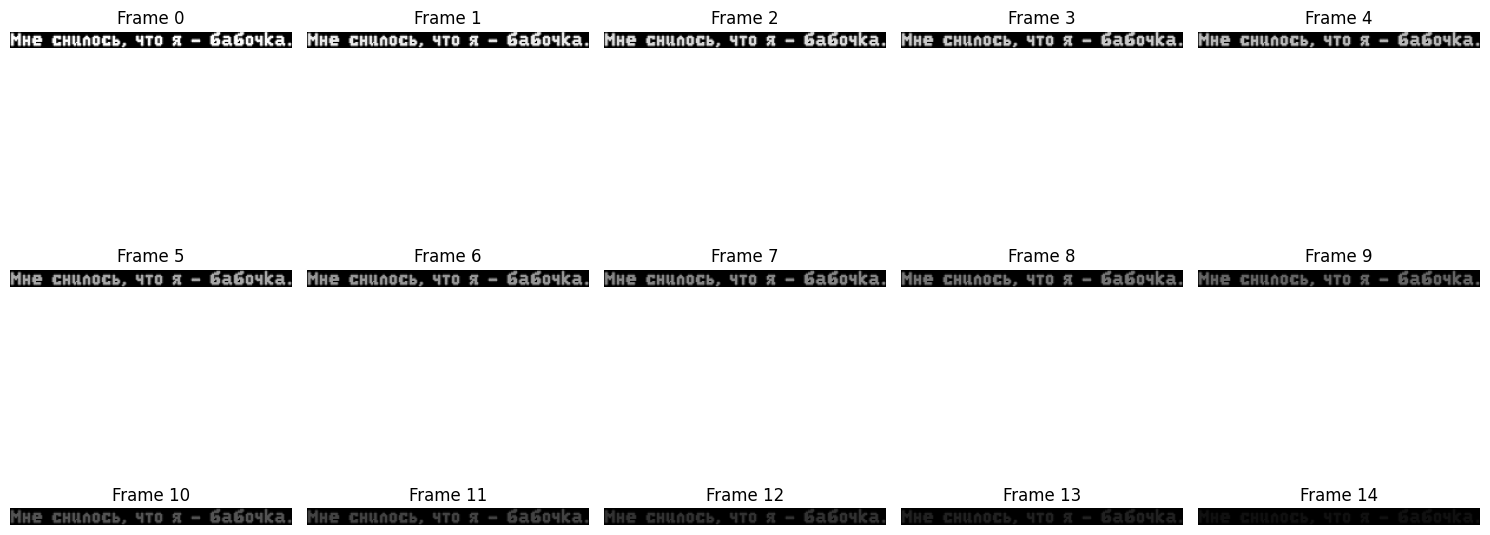

In [23]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

def fade_to_black_simple(image_path, num_frames=15):
    """
    Плавное превращение изображения в черное за num_frames кадров
    Простое линейное уменьшение значений пикселей
    """
    # Загрузка изображения
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img, dtype=np.float32)
    
    frames = []
    
    for i in range(num_frames + 1):
        # Коэффициент затемнения (от 1 до 0)
        factor = 1 - (i / num_frames)
        
        # Применение коэффициента ко всем пикселям
        darkened = img_array * factor
        darkened = np.clip(darkened, 0, 255).astype(np.uint8)
        
        frames.append(Image.fromarray(darkened))
    
    return frames

# Использование
frames = fade_to_black_simple('RedrawFr1/phrase_1.png', num_frames=15)

# Показ всех кадров
fig, axes = plt.subplots(3, 5, figsize=(15, 9))
for idx, ax in enumerate(axes.flat):
    if idx < len(frames):
        ax.imshow(frames[idx])
        ax.set_title(f'Frame {idx}')
        ax.axis('off')
plt.tight_layout()
plt.show()

# Показ первого и последнего кадра
display(frames[0])  # Исходное изображение
display(frames[-1]) # Полностью черное

#### С сохранением файлов

In [2]:
from PIL import Image
import numpy as np
import os

def fade_to_black_save(image_path, output_dir='frames', num_frames=15):
    """
    Создание кадров затемнения и сохранение их в файлы
    """
    # Создание директории для кадров
    os.makedirs(output_dir, exist_ok=True)
    
    # Загрузка изображения
    img = Image.open(image_path).convert('RGB')
    img_array = np.array(img, dtype=np.float32)
    
    frames = []
    
    for i in range(num_frames + 1):
        # Коэффициент затемнения
        factor = 1 - (i / num_frames)
        
        # Затемнение
        darkened = img_array * factor
        darkened = np.clip(darkened, 0, 255).astype(np.uint8)
        
        # Сохранение кадра
        frame_img = Image.fromarray(darkened)
        frame_path = os.path.join(output_dir, f'frame_end_{i:03d}.png')
        frame_img.save(frame_path)
        
        frames.append(frame_img)
        print(f"Сохранен кадр {i}: {frame_path}")
    
    return frames

# Использование
frames = fade_to_black_save('phrase3/phrase_3.png', 'phrase3', num_frames=20)

Сохранен кадр 0: phrase3\frame_end_000.png
Сохранен кадр 1: phrase3\frame_end_001.png
Сохранен кадр 2: phrase3\frame_end_002.png
Сохранен кадр 3: phrase3\frame_end_003.png
Сохранен кадр 4: phrase3\frame_end_004.png
Сохранен кадр 5: phrase3\frame_end_005.png
Сохранен кадр 6: phrase3\frame_end_006.png
Сохранен кадр 7: phrase3\frame_end_007.png
Сохранен кадр 8: phrase3\frame_end_008.png
Сохранен кадр 9: phrase3\frame_end_009.png
Сохранен кадр 10: phrase3\frame_end_010.png
Сохранен кадр 11: phrase3\frame_end_011.png
Сохранен кадр 12: phrase3\frame_end_012.png
Сохранен кадр 13: phrase3\frame_end_013.png
Сохранен кадр 14: phrase3\frame_end_014.png
Сохранен кадр 15: phrase3\frame_end_015.png
Сохранен кадр 16: phrase3\frame_end_016.png
Сохранен кадр 17: phrase3\frame_end_017.png
Сохранен кадр 18: phrase3\frame_end_018.png
Сохранен кадр 19: phrase3\frame_end_019.png
Сохранен кадр 20: phrase3\frame_end_020.png


#### Изменение кадров с 20 по 95

In [29]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    """
    
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    pixel = img[0, 0]  # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = pixel
    
    return img
    
    
def paste_opencv(b_img, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    b_img[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return b_img

    
# Параметры
input_path = "Frames1/"      # путь к исходному изображению
overlay_path = 'phrase1/'              # путь к переведенной надписи
output_path = "RedrawFr1/"  # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 52, 103    # координаты верхнего левого угла
width = 224       # ширина области
height = 22      # высота области

num_frame = 14

for i in range(76):
    base_img = remove_rectangular_area(input_path + f"MV1C.STR[0][{i+20:04d}].bmp", overlay_path, x, y, width, height)
    
    if (i < 14):
        result = paste_opencv(base_img, overlay_path + f"frame_{num_frame:03d}.png", position=(41, 106))
        num_frame -= 1
    elif (i < 61):
        result = paste_opencv(base_img, overlay_path + f"frame_000.png", position=(41, 106))
    else:
        result = paste_opencv(base_img, overlay_path + f"frame_{num_frame:03d}.png", position=(41, 106))
        num_frame += 1

    cv2.imwrite(output_path + f"MV1C.STR[0][{i+20:04d}].bmp", result)
    print(f"Изображение сохранено: " + output_path + f"MV1C.STR[0][{i+20:04d}].bmp")


Изображение сохранено: RedrawFr/MV1C.STR[0][0020].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0021].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0022].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0023].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0024].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0025].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0026].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0027].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0028].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0029].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0030].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0031].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0032].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0033].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0034].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0035].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0036].bmp
Изображение сохранено: RedrawFr/MV1C.STR[0][0037].bmp
Изображение сохранено: Redra

#### Изменение кадров с 103 по 224

In [3]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    """
    
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    pixel = img[0, 0]  # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = pixel
    
    return img
    
    
def paste_opencv(b_img, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    b_img[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return b_img

    
# Параметры
input_path = "Frames1/"      # путь к исходному изображению
overlay_path = 'phrase2/'              # путь к переведенной надписи
output_path = "RedrawFr2/"  # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 17, 49    # координаты верхнего левого угла
width = 300       # ширина области
height = 213      # высота области

num_frame = 17
num_frame_end = 1

for i in range(122):
    base_img = remove_rectangular_area(input_path + f"MV1C.STR[0][{i+103:04d}].bmp", overlay_path, x, y, width, height)
    
    if i < 17:
        result = paste_opencv(base_img, overlay_path + f"frame_{num_frame:03d}.png", position=(29, 94))
        num_frame -= 1
    elif i < 101:
        result = paste_opencv(base_img, overlay_path + f"frame_000.png", position=(29, 94))
    else:
        result = paste_opencv(base_img, overlay_path + f"frame_end_{num_frame_end:03d}.png", position=(29, 94))
        num_frame_end += 1

    cv2.imwrite(output_path + f"MV1C.STR[0][{i+103:04d}].bmp", result)
    print(f"Изображение сохранено: " + output_path + f"MV1C.STR[0][{i+103:04d}].bmp")


Изображение сохранено: RedrawFr2/MV1C.STR[0][0103].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0104].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0105].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0106].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0107].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0108].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0109].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0110].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0111].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0112].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0113].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0114].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0115].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0116].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0117].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0118].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0119].bmp
Изображение сохранено: RedrawFr2/MV1C.STR[0][0120].bmp
Изображени

#### Изменение кадров с 231 по 333

In [13]:
import cv2
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

def remove_rectangular_area(image_path, output_path, x, y, w, h):
    """
    Удаляет прямоугольную область на изображении, заливая её указанным цветом.
    """
    
    # Загрузка изображения
    img = cv2.imread(image_path)
    
    if img is None:
        print("Ошибка: не удалось загрузить изображение")
        return False
    
    # Проверка границ прямоугольника
    height, width = img.shape[:2]
    x1, y1 = max(0, x), max(0, y)
    x2, y2 = min(width, x + w), min(height, y + h)
    
    pixel = img[0, 0]  # В OpenCV цвета идут в порядке BGR (Blue, Green, Red)
    
    # Заливка прямоугольной области
    img[y1:y2, x1:x2] = pixel
    
    return img
    
    
def paste_opencv(b_img, o_path, position=(0, 0)):
    """
    Вставка с помощью OpenCV
    """
    # Загрузка изображений
    overlay = cv2.imread(o_path)
    
    x, y = position
    # Вставка
    b_img[y:y+overlay.shape[0], x:x+overlay.shape[1]] = overlay
    
    return b_img

    
# Параметры
input_path = "Frames1/"      # путь к исходному изображению
overlay_path = 'phrase3/'              # путь к переведенной надписи
output_path = "RedrawFr3/"  # путь для сохранения

# Координаты и размеры удаляемой области
x, y = 14, 57    # координаты верхнего левого угла
width = 299       # ширина области
height = 130      # высота области

num_frame = 21
num_frame_end = 1

for i in range(103):
    base_img = remove_rectangular_area(input_path + f"MV1C.STR[0][{i+231:04d}].bmp", overlay_path, x, y, width, height)
    
    if i < 21:
        result = paste_opencv(base_img, overlay_path + f"frame_{num_frame:03d}.png", position=(12, 102))
        num_frame -= 1
    elif i < 84:
        result = paste_opencv(base_img, overlay_path + f"frame_000.png", position=(12, 102))
    else:
        result = paste_opencv(base_img, overlay_path + f"frame_end_{num_frame_end:03d}.png", position=(12, 102))
        num_frame_end += 1

    cv2.imwrite(output_path + f"MV1C.STR[0][{i+231:04d}].bmp", result)
    print(f"Изображение сохранено: " + output_path + f"MV1C.STR[0][{i+231:04d}].bmp")


Изображение сохранено: RedrawFr3/MV1C.STR[0][0231].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0232].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0233].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0234].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0235].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0236].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0237].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0238].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0239].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0240].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0241].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0242].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0243].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0244].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0245].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0246].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0247].bmp
Изображение сохранено: RedrawFr3/MV1C.STR[0][0248].bmp
Изображени